# see the effect of binning activity on d2

In [1]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from src.analysis.prox_crit import calc_db, minimize_klr_b
from src.analysis.prox_crit_confounds import CALC_DB_DEFAULTS, plot_d2_sweep
from src.models.branching_model.branching_network import (
    distance_to_criticality,
    params_for_distance,
    bn_aa_population,
    stationary_rate_aa,
    stationary_var_aa,
)
from src.config.paths import FIGURES_DIR
from src.utils.persist import save, load, list_saves, prune
from src.utils.binning import binning
from src.utils.plotting import PET10, add_linear_inset, save_fig
from src.analysis.timescales import get_autocorrelation

PET10.use()  # default colour cycle
save_figures = True  # plots -> results/figures/prox_crit_confounds/ (sweep plots only when not debugging)

### some visuals first

Saved results\figures\prox_crit_confounds\binning_example_activity.png (367 kB, new)


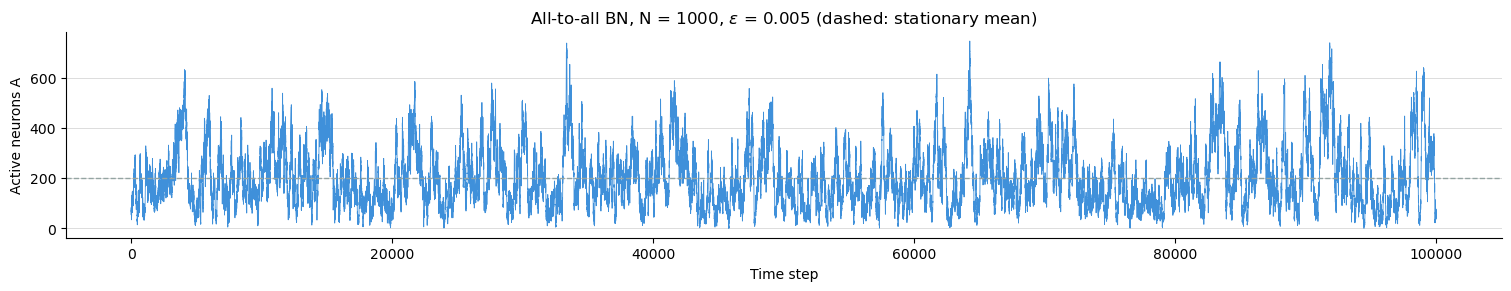

In [2]:
# simulate a small network
N = int(1e3)
T = int(1e5)
R = 1
steady_rate = 0.2
distance = 5e-3

sigma, h = params_for_distance(rate=steady_rate, distance=distance)
A = bn_aa_population(N=N, sigma=sigma, T=T, h=h, R=R, seed=0)
activity = A[0]

fig, ax = plt.subplots(figsize=(15, 2.8), layout="constrained")
ax.plot(activity, linewidth=0.6, color=PET10.blue)
ax.axhline(stationary_rate_aa(sigma, h) * N, color=PET10.grey, linewidth=1, linestyle="--")
ax.set(
    xlabel="Time step",
    ylabel="Active neurons A",
    title=rf"All-to-all BN, N = {N}, $\epsilon$ = {distance:g} (dashed: stationary mean)",
)
ax.grid(axis="y", alpha=0.5, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
if save_figures:
    save_fig(fig, "prox_crit_confounds/binning_example_activity")
plt.show()

Saved results\figures\prox_crit_confounds\binning_example_binned_acf.png (1.1 MB, new)


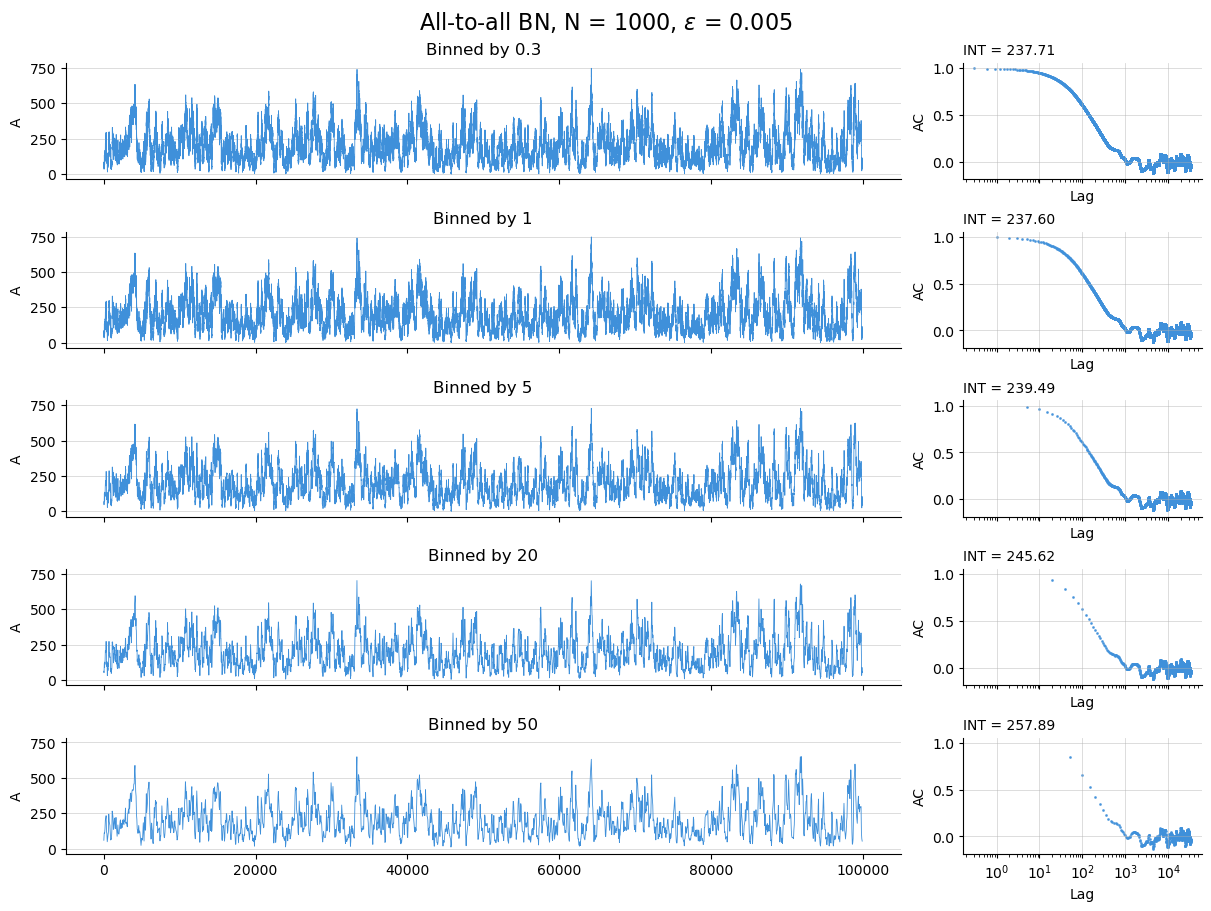

In [3]:
# bin the activity
binnings = [0.3, 1, 5, 20, 50]
fig, axs = plt.subplots(
    len(binnings),
    2,
    figsize=(12, 9),
    gridspec_kw={"width_ratios": [3.5, 1]},
    layout="constrained",
    sharex="col",
    sharey="col",
)
x = np.arange(len(activity))

for i, fuse in enumerate(binnings):
    binned_activity = binning(activity, fuse=fuse, mode="mean")
    t_binned = np.arange(len(binned_activity)) * fuse

    max_lag = int(len(binned_activity) / 3)
    autocorr, lags, [INT, INT_01, acw_0, acw_01] = get_autocorrelation(
        binned_activity, max_lag, dt=fuse
    )
    axs[i, 0].plot(t_binned, binned_activity, linewidth=0.6, color=PET10.blue)
    axs[i, 0].set(
        ylabel="A",
        title=rf"Binned by {fuse}",
    )
    axs[i, 0].grid(axis="y", alpha=0.5, linewidth=0.6)
    axs[i, 0].spines[["top", "right"]].set_visible(False)

    # Right: autocorrelation of the same realization
    axs[i, 1].scatter(
        lags,
        autocorr,
        s=1,
        alpha=0.8,
    )
    axs[i, 1].set_ylabel("AC")
    axs[i, 1].set_xlabel("Lag")
    axs[i, 1].grid(alpha=0.5, linewidth=0.6)
    axs[i, 1].spines[["top", "right"]].set_visible(False)
    axs[i, 1].tick_params(direction="out", length=3)
    axs[i, 1].set_xscale("log")

    axs[i, 1].set_title(
        rf"INT = {INT:.2f}",
        loc="left",
        fontsize=10,
    )

fig.suptitle(f"All-to-all BN, N = {N}, $\epsilon$ = {distance:g}", fontsize=16)

if save_figures:
    save_fig(fig, "prox_crit_confounds/binning_example_binned_acf")
plt.show()

In [4]:
# define parameters
debugging = False

N, T, R = int(1e4), int(1e5), 5
steady_rate = 0.2
seed = 123
distances = np.logspace(start=-4, stop=0, num=50, base=10)

# Bin widths ("fuse"), in time steps:
#   < 1 : 0.3 and 0.6 are not of the form 1/integer, so steps are split unevenly between bins
#   = 1 : no binning, the reference
#   > 1 : every second power of two
fuses = [0.3, 0.6, 1, 2, 8, 32, 128]

if debugging:
    N, T, R = int(1e3), int(1e3), 2
    distances = np.logspace(start=-2, stop=0, num=4, base=10)
    fuses = [0.6, 1, 8]  # one of each kind; at T = 1e3, fuse = 8 still leaves 125 bins

In [5]:
# generate the data
db_results = []  # db_results[i][j][r] = DbResult for distances[i], fuses[j], replica r
for i, distance in enumerate(distances):
    sigma, h = params_for_distance(rate=steady_rate, distance=distance)
    A = bn_aa_population(N=N, sigma=sigma, T=T, h=h, R=R, seed=seed * i)

    results_this_distance = []
    for fuse in fuses:
        A_binned = binning(
            A, fuse=fuse, mode="sum"
        )  # bins all replicas at once (last axis = time)

        results_this_fuse = []
        for r in range(R):
            # delta_t: one bin lasts `fuse` steps, so d2 stays in bits per original step
            result = calc_db(x=A_binned[r], **dict(CALC_DB_DEFAULTS, delta_t=fuse))
            results_this_fuse.append(result)

        results_this_distance.append(results_this_fuse)

    db_results.append(results_this_distance)
    print(f"distance {i + 1}/{len(distances)} done")

path = save(
    "bn_aa_db_binning" + ("_debug" if debugging else ""),
    db_results=db_results,
    distances=distances,
    fuses=fuses,
    params=dict(N=N, T=T, R=R, steady_rate=steady_rate, seed=seed),
    keep=(
        1 if debugging else None
    ),  # debug runs: keep only the 3 newest; real runs: keep all
)

distance 1/50 done
distance 2/50 done
distance 3/50 done
distance 4/50 done
distance 5/50 done
distance 6/50 done
distance 7/50 done
distance 8/50 done
distance 9/50 done
distance 10/50 done
distance 11/50 done
distance 12/50 done
distance 13/50 done
distance 14/50 done
distance 15/50 done
distance 16/50 done
distance 17/50 done
distance 18/50 done
distance 19/50 done
distance 20/50 done
distance 21/50 done
distance 22/50 done
distance 23/50 done
distance 24/50 done
distance 25/50 done
distance 26/50 done
distance 27/50 done
distance 28/50 done
distance 29/50 done
distance 30/50 done
distance 31/50 done
distance 32/50 done
distance 33/50 done
distance 34/50 done
distance 35/50 done
distance 36/50 done
distance 37/50 done
distance 38/50 done
distance 39/50 done
distance 40/50 done
distance 41/50 done
distance 42/50 done
distance 43/50 done
distance 44/50 done
distance 45/50 done
distance 46/50 done
distance 47/50 done
distance 48/50 done
distance 49/50 done
distance 50/50 done
Saved dat

Loaded bn_aa_db_binning__2026-11-20_003205.pkl (725.3 kB, git c0b24df)
  db_results : list, len 50
  distances  : ndarray float64 (50,)
  fuses      : [0.3, 0.6, 1, 2, 8, 32, 128]
  params     : {'N': 10000, 'T': 100000, 'R': 5, 'steady_rate': 0.2, 'seed': 123}
Saved results\figures\prox_crit_confounds\d2_vs_eps_binning.png (560 kB, new)


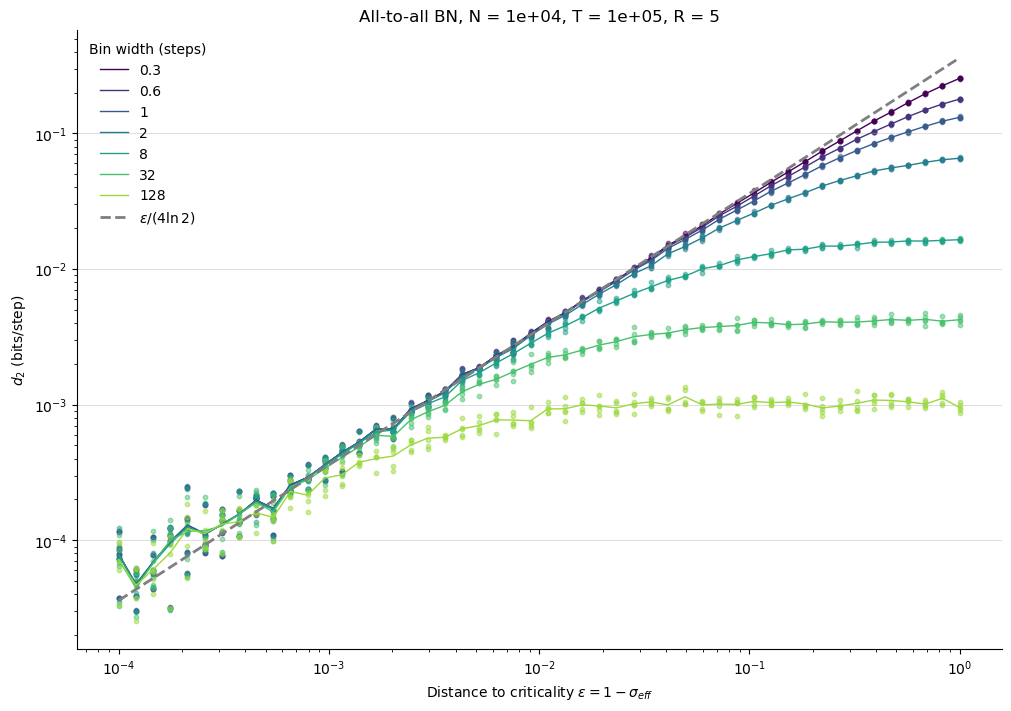

In [6]:
# plot it
data = load(
    "bn_aa_db_binning" + ("_debug" if debugging else "")
)  # after a kernel restart: load("bn_aa_db_binning") gets the newest run

p = data.params
fig, ax = plot_d2_sweep(
    distances=data.distances,
    db_results=data.db_results,
    values=data.fuses,
    legend_title="Bin width (steps)",
    title=rf"All-to-all BN, N = {p['N']:.4g}, T = {p['T']:.4g}, R = {p['R']:.4g}",
)
if save_figures and not debugging:
    save_fig(fig, "prox_crit_confounds/d2_vs_eps_binning")
plt.show()